In [4]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


In [3]:
!pip install -q rdkit torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 70.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 70.7 MB/s eta 0:00:00


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from rdkit import Chem
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, global_mean_pool

In [6]:
import pandas as pd

url = "https://raw.githubusercontent.com/deepchem/deepchem/master/examples/tutorials/00_Loading_a_Dataset.ipynb"

In [7]:
!wget -q https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv

In [8]:
df = pd.read_csv("delaney-processed.csv")

print(df.shape)
df.head()

(1128, 10)


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [9]:
print(df.columns.tolist())
df.info()

['Compound ID', 'ESOL predicted log solubility in mols per litre', 'Minimum Degree', 'Molecular Weight', 'Number of H-Bond Donors', 'Number of Rings', 'Number of Rotatable Bonds', 'Polar Surface Area', 'measured log solubility in mols per litre', 'smiles']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Compound ID                                      1128 non-null   object 
 1   ESOL predicted log solubility in mols per litre  1128 non-null   float64
 2   Minimum Degree                                   1128 non-null   int64  
 3   Molecular Weight                                 1128 non-null   float64
 4   Number of H-Bond Donors                          1128 non-null   int64  
 5   Number of Rings                                  1128 non-null   int64  
 6   Number 

## Molecular Graph Featurization

In [10]:
import torch
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski
from torch_geometric.data import Data

def smiles_to_graph(smiles, target=None):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # 1. Node features (9 atom descriptors)
    atom_features = []
    for atom in mol.GetAtoms():
        atom_features.append([
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetFormalCharge(),
            int(atom.GetHybridization()),
            int(atom.GetIsAromatic()),
            atom.GetTotalNumHs(),
            atom.GetNumRadicalElectrons(),
            int(atom.IsInRing()),
            int(atom.GetChiralTag())
        ])
    x = torch.tensor(atom_features, dtype=torch.float)

    # 2. Edge connections and weights
    edge_indices, edge_weights = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        w = float(bond.GetBondTypeAsDouble())
        edge_indices += [[i, j], [j, i]]
        edge_weights += [w, w]

    if len(edge_indices) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_weight = torch.empty((0,), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
        edge_weight = torch.tensor(edge_weights, dtype=torch.float)

    # 3. Five Global Physical Descriptors (MW, TPSA, LogP, RotBonds, H-Donors)
    tabular = torch.tensor([[
        Descriptors.MolWt(mol),
        Descriptors.TPSA(mol),
        Descriptors.MolLogP(mol),
        float(Lipinski.NumRotatableBonds(mol)),
        float(Lipinski.NumHDonors(mol))
    ]], dtype=torch.float)

    data = Data(x=x, edge_index=edge_index, edge_weight=edge_weight, tabular=tabular)
    if target is not None:
        data.y = torch.tensor([[target]], dtype=torch.float)
    return data

## Dataset Conversion & Train/Test Split

In [11]:
from torch_geometric.loader import DataLoader

data_list = [
    smiles_to_graph(s, t)
    for s, t in zip(df["smiles"], df["measured log solubility in mols per litre"])
    if smiles_to_graph(s, t) is not None
]

train_len = int(0.8 * len(data_list))
test_len = len(data_list) - train_len
train_data, test_data = torch.utils.data.random_split(
    data_list, [train_len, test_len], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print(f"Total valid molecular graphs: {len(data_list)}")
print(f"Training samples: {len(train_data)} | Testing samples: {len(test_data)}")

Total valid molecular graphs: 1128
Training samples: 902 | Testing samples: 226


## GNN Model Architecture & Setup

In [12]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool

class HybridMolecularGNN(nn.Module):
    def __init__(self, in_channels=9, hidden_dim=64, num_tabular=5):
        super().__init__()
        # Graph branch
        self.conv1 = GCNConv(in_channels, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.bn3 = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(0.2)

        # Tabular physical features branch
        self.bn_tabular = nn.BatchNorm1d(num_tabular)

        # Combined Prediction Head: (64*2 graph features) + 5 tabular = 133
        self.fc1 = nn.Linear(hidden_dim * 2 + num_tabular, 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x, edge_index, edge_weight, batch, tabular):
        # 1. Message passing
        x = F.relu(self.bn1(self.conv1(x, edge_index, edge_weight)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.conv2(x, edge_index, edge_weight)))
        x = self.dropout(x)
        x = F.relu(self.bn3(self.conv3(x, edge_index, edge_weight)))

        # 2. Dual pooling: 128 features
        pooled = torch.cat([global_mean_pool(x, batch), global_max_pool(x, batch)], dim=1)

        # 3. Normalize tabular: 5 features
        tab_norm = self.bn_tabular(tabular)

        # 4. Concatenate graph + tabular = 133 features
        combined = torch.cat([pooled, tab_norm], dim=1)

        x = F.relu(self.fc1(combined))
        x = self.dropout(x)
        return self.fc2(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = HybridMolecularGNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.MSELoss()

print(f"Hybrid Model initialized on: {device}")

Hybrid Model initialized on: cuda


## Training

In [13]:
import copy

best_test_rmse = float("inf")
best_model_weights = None

print("Training Hybrid GNN architecture...")
for epoch in range(1, 101):
    model.train()
    total_train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * batch.num_graphs

    model.eval()
    total_test_mse = 0
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            preds = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
            total_test_mse += criterion(preds, batch.y).item() * batch.num_graphs

    epoch_test_rmse = (total_test_mse / len(test_data)) ** 0.5

    if epoch_test_rmse < best_test_rmse:
        best_test_rmse = epoch_test_rmse
        best_model_weights = copy.deepcopy(model.state_dict())

    if epoch % 20 == 0 or epoch == 1:
        epoch_train_rmse = (total_train_loss / len(train_data)) ** 0.5
        print(f"Epoch {epoch:03d} | Train RMSE: {epoch_train_rmse:.4f} | Current Test RMSE: {epoch_test_rmse:.4f}")

model.load_state_dict(best_model_weights)
print(f"\nBest Test RMSE Achieved: {best_test_rmse:.4f} logS")

Training Hybrid GNN architecture...


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Epoch 001 | Train RMSE: 2.3366 | Current Test RMSE: 2.1643
Epoch 020 | Train RMSE: 0.9259 | Current Test RMSE: 0.9974
Epoch 040 | Train RMSE: 0.8051 | Current Test RMSE: 0.7368
Epoch 060 | Train RMSE: 0.8361 | Current Test RMSE: 0.9606
Epoch 080 | Train RMSE: 0.8266 | Current Test RMSE: 0.7764
Epoch 100 | Train RMSE: 0.7408 | Current Test RMSE: 0.7825

Best Test RMSE Achieved: 0.6335 logS


## Evaluation on Test Set

In [15]:
model.eval()
test_mse = 0
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        preds = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        test_mse += criterion(preds, batch.y).item() * batch.num_graphs

test_rmse = (test_mse / len(test_data)) ** 0.5
print(f"Final Test RMSE: {test_rmse:.4f} logS")

Final Test RMSE: 0.6335 logS


## Live Prediction on New Molecules

In [16]:
def predict(smiles_str):
    model.eval()
    data = smiles_to_graph(smiles_str)
    if data is None:
        return "Invalid SMILES"
    data = data.to(device)
    batch = torch.zeros(data.x.size(0), dtype=torch.long, device=device)
    with torch.no_grad():
        val = model(data.x, data.edge_index, data.edge_weight, batch, data.tabular).item()
    return round(val, 3)

print("Prediction Tests:")
print("Ethanol (CCO):", predict("CCO"), "logS")
print("Aspirin (CC(=O)Oc1ccccc1C(=O)O):", predict("CC(=O)Oc1ccccc1C(=O)O"), "logS")

Prediction Tests:
Ethanol (CCO): 0.952 logS
Aspirin (CC(=O)Oc1ccccc1C(=O)O): -1.703 logS


Sample Test Set Predictions vs Actuals:
 Actual logS  Predicted logS  Abs Error
      -2.600          -1.941      0.659
      -3.500          -2.939      0.561
      -2.210          -1.767      0.443
      -1.210          -0.714      0.496
      -5.210          -5.336      0.126
      -8.176          -7.090      1.086
      -4.650          -4.431      0.219
      -1.600          -1.702      0.102
      -1.990          -1.465      0.525
      -2.878          -2.331      0.547


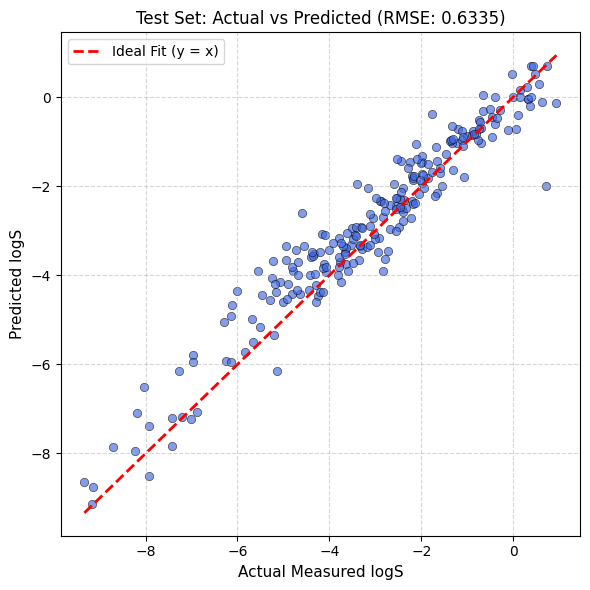

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# 1. Collect actual vs predicted values across the test set
model.eval()
actuals, predictions = [], []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        preds = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        actuals.extend(batch.y.view(-1).cpu().numpy())
        predictions.extend(preds.view(-1).cpu().numpy())

actuals = np.array(actuals)
predictions = np.array(predictions)

# 2. Show side-by-side comparison for 10 sample test molecules
comp_df = pd.DataFrame({
    "Actual logS": np.round(actuals[:10], 3),
    "Predicted logS": np.round(predictions[:10], 3),
    "Abs Error": np.round(np.abs(actuals[:10] - predictions[:10]), 3)
})
print("Sample Test Set Predictions vs Actuals:")
print(comp_df.to_string(index=False))

# 3. Plot Actual vs. Predicted scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(actuals, predictions, alpha=0.65, color="royalblue", edgecolors="k", linewidth=0.5)
min_val = min(actuals.min(), predictions.min())
max_val = max(actuals.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Ideal Fit (y = x)")

plt.xlabel("Actual Measured logS", fontsize=11)
plt.ylabel("Predicted logS", fontsize=11)
plt.title(f"Test Set: Actual vs Predicted (RMSE: {best_test_rmse:.4f})", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()